# Experiment 019: analysis plots

These plots compare the restarted continuation on the weak seed 1 artifact
from experiment 018 with the strong seed 2 artifact from experiment 019. Both
continuations restore the exact step-500 state and apply 499 nonzero updates
under the revived schedule. The comparison is exploratory because both artifacts
were selected after earlier test results were known.

In [1]:
import json, os, sys
ROOT = '..' if os.path.basename(os.getcwd()) == 'notebooks' else '.'
sys.path.insert(0, os.path.abspath(ROOT))
import matplotlib.pyplot as plt
import numpy as np
from analysis.plotting import heatmap_text_color
from analysis.stats import _read_preds, align_pred_rows
from data.subjects import tier_of, TIERS

R = os.path.join(ROOT, 'results')
FIGDIR = os.path.join(ROOT, 'analysis', 'figures', '019_1')
os.makedirs(FIGDIR, exist_ok=True)

def accuracy(path):
    rows = _read_preds(path)
    assert len(rows) == 1884, f'{path}: expected 1884 rows, found {len(rows)}'
    return sum(r['correct'] for r in rows) / len(rows)

def paired_rows(old_path, new_path):
    old, new = align_pred_rows(_read_preds(old_path), _read_preds(new_path))
    assert len(old) == len(new) == 1884
    return old, new

# load the saved artifacts used in every comparison
paths = {
    1: {
        'step500': f'{R}/006_COLAB_FULL_B05_sft_grpo_seed1/grpo_preds.jsonl',
        'step1000': f'{R}/018_ext_B05_seed1_step1000/grpo_preds.jsonl',
        'selected': f'{R}/017_selector_B05_seed1_step450/grpo_preds.jsonl',
        'selected_step': 450,
        'summary': f'{R}/018_ext_B05_seed1_step1000/comparison_summary.json',
        'curve': f'{R}/018_ext_B05_seed1_step1000/combined_reward_curve.json',
        'trainlog': f'{R}/018_ext_B05_seed1_step1000/grpo_trainlog.json',
    },
    2: {
        'step500': f'{R}/006_COLAB_FULL_B05_sft_grpo_seed2/grpo_preds.jsonl',
        'step1000': f'{R}/019_ext_B05_seed2_step1000/grpo_preds.jsonl',
        'selected': f'{R}/017_selector_B05_seed2_step250/grpo_preds.jsonl',
        'selected_step': 250,
        'summary': f'{R}/019_ext_B05_seed2_step1000/comparison_summary.json',
        'curve': f'{R}/019_ext_B05_seed2_step1000/combined_reward_curve.json',
        'trainlog': f'{R}/019_ext_B05_seed2_step1000/grpo_trainlog.json',
    },
}
for seed in paths:
    paths[seed]['stats'] = json.load(open(paths[seed]['summary']))
    paths[seed]['rows500'], paths[seed]['rows1000'] = paired_rows(paths[seed]['step500'], paths[seed]['step1000'])
    paths[seed]['acc500'] = accuracy(paths[seed]['step500'])
    paths[seed]['acc1000'] = accuracy(paths[seed]['step1000'])
    paths[seed]['selected_acc'] = accuracy(paths[seed]['selected'])
    measured_delta = paths[seed]['acc1000'] - paths[seed]['acc500']
    assert abs(measured_delta - paths[seed]['stats']['delta']) < 1e-12

mcsft_scores = [accuracy(f'{R}/007_p8_COLAB_FULL_B05_sft_only_seed{s}/sft_preds.jsonl') for s in (0, 1, 2)]
mcsft_mean = sum(mcsft_scores) / len(mcsft_scores)
base_probe = accuracy(f'{R}/base_evals/006_COLAB_FULL_B05/base_logprob_preds.jsonl')
print(f'seed 1: {paths[1]["acc500"]:.3f} -> {paths[1]["acc1000"]:.3f}, delta {paths[1]["stats"]["delta"]:+.3f}')
print(f'seed 2: {paths[2]["acc500"]:.3f} -> {paths[2]["acc1000"]:.3f}, delta {paths[2]["stats"]["delta"]:+.3f}')
print(f'mc-sft mean {mcsft_mean:.3f}, range {min(mcsft_scores):.3f}-{max(mcsft_scores):.3f}, base probe {base_probe:.3f}')

seed 1: 0.315 -> 0.515, delta +0.200
seed 2: 0.506 -> 0.538, delta +0.032
mc-sft mean 0.534, range 0.530-0.538, base probe 0.567


## Accuracy-reward trajectories

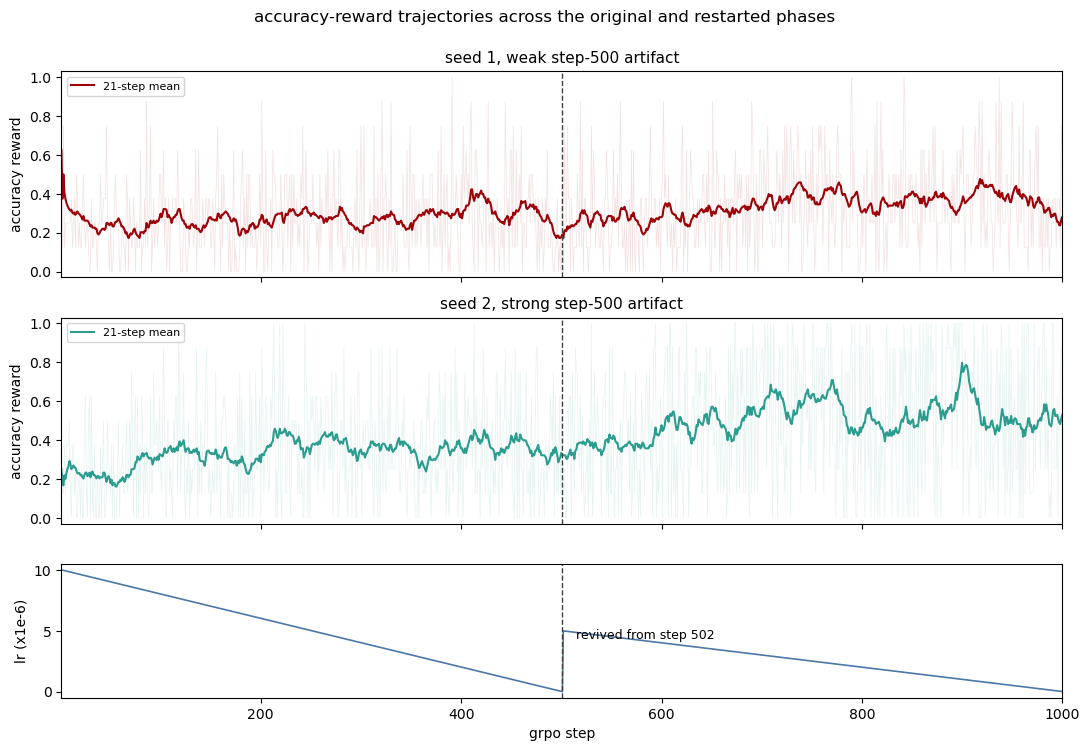

In [2]:
# plot both accuracy-reward trajectories with the shared learning-rate schedule
def rolling(values, window=21):
    return [sum(values[max(0, i-window+1):i+1]) / len(values[max(0, i-window+1):i+1])
            for i in range(len(values))]

curves = {}
for seed in paths:
    raw = json.load(open(paths[seed]['curve']))
    steps = sorted(int(s) for s in raw)
    assert steps == list(range(1, 1001))
    curves[seed] = [raw[str(s)] for s in steps]
trainlog = json.load(open(paths[2]['trainlog']))
lr = {int(e['step']): float(e['learning_rate']) for e in trainlog if 'step' in e and 'learning_rate' in e}
assert sorted(lr) == list(range(1, 1001))

fig, axes = plt.subplots(3, 1, figsize=(11, 7.5), sharex=True,
                         gridspec_kw={'height_ratios': [1, 1, 0.65]})
colours = {1: '#9d0208', 2: '#2a9d8f'}
labels = {1: 'seed 1, weak step-500 artifact', 2: 'seed 2, strong step-500 artifact'}
for ax, seed in zip(axes[:2], (1, 2)):
    ax.plot(steps, curves[seed], color=colours[seed], lw=0.5, alpha=0.12)
    ax.plot(steps, rolling(curves[seed]), color=colours[seed], lw=1.5, label='21-step mean')
    ax.axvline(500.5, color='0.25', ls='--', lw=1)
    ax.set_ylabel('accuracy reward')
    ax.set_ylim(-0.03, 1.03)
    ax.set_title(labels[seed], fontsize=11)
    ax.legend(loc='upper left', fontsize=8)
axes[2].plot(steps, [lr[s] * 1e6 for s in steps], color='#4c78a8', lw=1.2)
axes[2].axvline(500.5, color='0.25', ls='--', lw=1)
axes[2].text(515, 4.35, 'revived from step 502', fontsize=9)
axes[2].set_ylabel('lr (x1e-6)')
axes[2].set_xlabel('grpo step')
axes[2].set_xlim(1, 1000)
fig.suptitle('accuracy-reward trajectories across the original and restarted phases', y=0.995)
fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, 'fig_recovery_curves.png'), dpi=200, bbox_inches='tight')
plt.show()

## Evaluated checkpoints and continuation endpoints

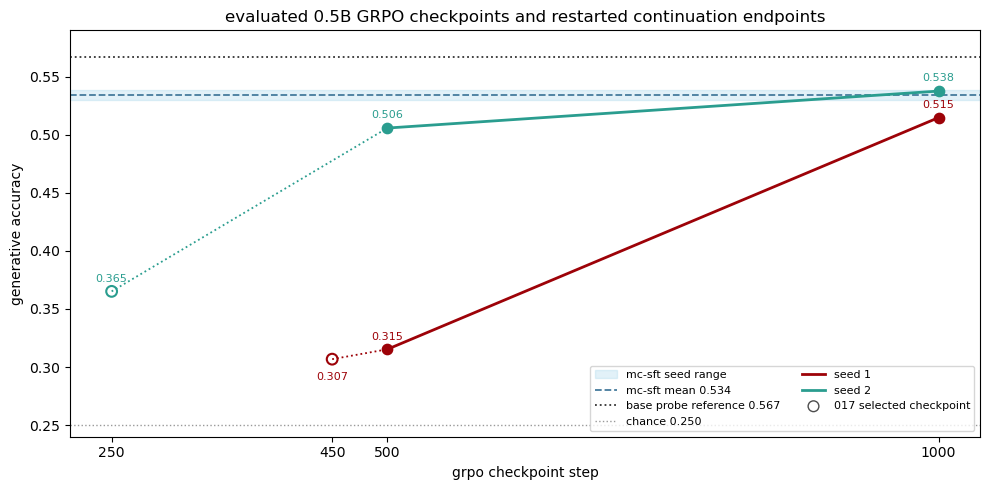

In [3]:
# compare the evaluated checkpoints with the restarted endpoints
fig, ax = plt.subplots(figsize=(10, 5))
ax.axhspan(min(mcsft_scores), max(mcsft_scores), color='#8ecae6', alpha=0.25, label='mc-sft seed range')
ax.axhline(mcsft_mean, color='#457b9d', ls='--', lw=1.3, label=f'mc-sft mean {mcsft_mean:.3f}')
ax.axhline(base_probe, color='0.2', ls=':', lw=1.3, label=f'base probe reference {base_probe:.3f}')
ax.axhline(0.25, color='0.6', ls=':', lw=1, label='chance 0.250')
for seed in (1, 2):
    p = paths[seed]
    c = colours[seed]
    pick_step = p['selected_step']
    ax.plot([pick_step, 500], [p['selected_acc'], p['acc500']], color=c, ls=':', lw=1.3)
    ax.plot([500, 1000], [p['acc500'], p['acc1000']], color=c, lw=2, label=f'seed {seed}')
    ax.scatter([pick_step], [p['selected_acc']], s=60, facecolors='none', edgecolors=c, linewidths=1.5, zorder=3)
    ax.scatter([500, 1000], [p['acc500'], p['acc1000']], s=55, color=c, zorder=3)
    points = [(pick_step, p['selected_acc']), (500, p['acc500']), (1000, p['acc1000'])]
    for step, value in points:
        offset = -15 if seed == 1 and step == pick_step else 7
        ax.annotate(f'{value:.3f}', (step, value), xytext=(0, offset), textcoords='offset points',
                    ha='center', fontsize=8, color=c)
ax.scatter([], [], s=60, facecolors='none', edgecolors='0.3', label='017 selected checkpoint')
ax.set_xticks([250, 450, 500, 1000])
ax.set_xlabel('grpo checkpoint step')
ax.set_ylabel('generative accuracy')
ax.set_ylim(0.24, 0.59)
ax.set_title('evaluated 0.5B GRPO checkpoints and restarted continuation endpoints')
ax.legend(fontsize=8, loc='lower right', ncol=2)
fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, 'fig_checkpoint_endpoints.png'), dpi=200, bbox_inches='tight')
plt.show()

## Paired effect sizes

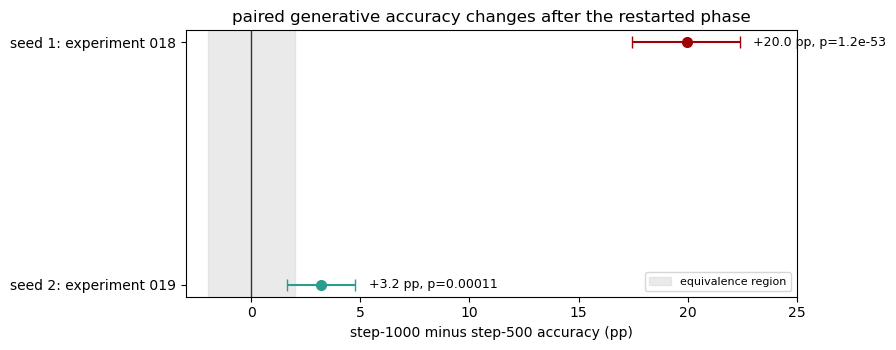

In [4]:
# plot the paired accuracy changes with bootstrap confidence intervals
fig, ax = plt.subplots(figsize=(9, 3.6))
seeds = [1, 2]
y = np.array([1, 0])
deltas = np.array([paths[s]['stats']['delta'] * 100 for s in seeds])
lo = np.array([paths[s]['stats']['ci'][0] * 100 for s in seeds])
hi = np.array([paths[s]['stats']['ci'][1] * 100 for s in seeds])
ax.axvspan(-2, 2, color='0.85', alpha=0.55, label='equivalence region')
ax.axvline(0, color='0.2', lw=1)
for i, seed in enumerate(seeds):
    ax.errorbar(deltas[i], y[i], xerr=[[deltas[i] - lo[i]], [hi[i] - deltas[i]]],
                fmt='o', ms=7, capsize=4, color=colours[seed])
    ax.text(hi[i] + 0.6, y[i], f'{deltas[i]:+.1f} pp, p={paths[seed]["stats"]["p"]:.2g}',
            va='center', fontsize=9)
ax.set_yticks(y)
ax.set_yticklabels(['seed 1: experiment 018', 'seed 2: experiment 019'])
ax.set_xlabel('step-1000 minus step-500 accuracy (pp)')
ax.set_xlim(-3, 25)
ax.set_title('paired generative accuracy changes after the restarted phase')
ax.legend(fontsize=8, loc='lower right')
fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, 'fig_paired_effects.png'), dpi=200, bbox_inches='tight')
plt.show()

## Accuracy change by tier

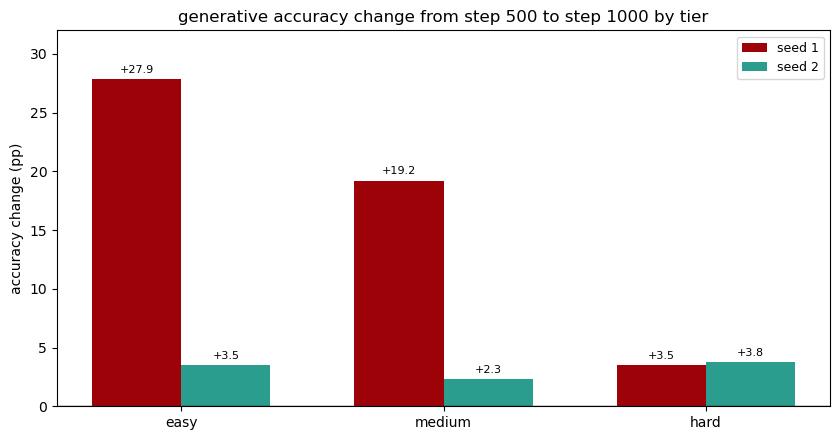

In [5]:
# compare the continuation gain on each difficulty tier
tier_changes = {seed: [(paths[seed]['stats']['tiers'][tier][0] - paths[seed]['stats']['tiers'][tier][1]) * 100
                       for tier in TIERS] for seed in (1, 2)}
x = np.arange(len(TIERS))
width = 0.34
fig, ax = plt.subplots(figsize=(8.5, 4.5))
bars1 = ax.bar(x - width/2, tier_changes[1], width, color=colours[1], label='seed 1')
bars2 = ax.bar(x + width/2, tier_changes[2], width, color=colours[2], label='seed 2')
ax.bar_label(bars1, labels=[f'{v:+.1f}' for v in tier_changes[1]], padding=3, fontsize=8)
ax.bar_label(bars2, labels=[f'{v:+.1f}' for v in tier_changes[2]], padding=3, fontsize=8)
ax.axhline(0, color='0.2', lw=1)
ax.set_xticks(x)
ax.set_xticklabels(TIERS)
ax.set_ylabel('accuracy change (pp)')
ax.set_ylim(0, 32)
ax.set_title('generative accuracy change from step 500 to step 1000 by tier')
ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, 'fig_tier_changes.png'), dpi=200, bbox_inches='tight')
plt.show()

## Paired answer changes

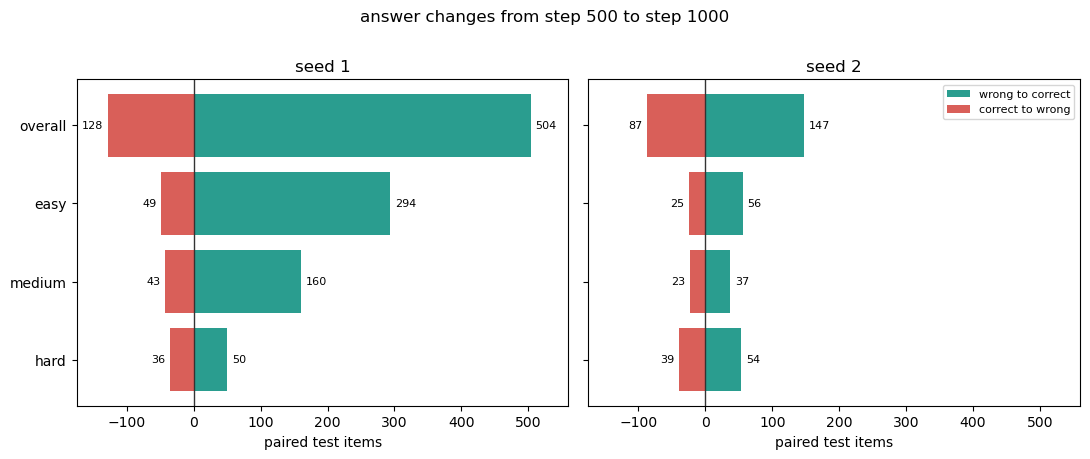

In [6]:
# count wrong-to-correct and correct-to-wrong changes for both continuations
def transition_counts(old, new):
    groups = ['overall'] + list(TIERS)
    gained, lost = [], []
    for group in groups:
        pairs = [(a, b) for a, b in zip(old, new)
                 if group == 'overall' or tier_of(a['subject']) == group]
        gained.append(sum((not a['correct']) and b['correct'] for a, b in pairs))
        lost.append(sum(a['correct'] and (not b['correct']) for a, b in pairs))
    return groups, gained, lost

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)
for ax, seed in zip(axes, (1, 2)):
    groups, gained, lost = transition_counts(paths[seed]['rows500'], paths[seed]['rows1000'])
    y = np.arange(len(groups))
    ax.barh(y, gained, color='#2a9d8f', label='wrong to correct')
    ax.barh(y, [-v for v in lost], color='#d95f59', label='correct to wrong')
    for row, (up, down) in enumerate(zip(gained, lost)):
        ax.text(up + 7, row, str(up), va='center', fontsize=8)
        ax.text(-down - 7, row, str(down), va='center', ha='right', fontsize=8)
    ax.axvline(0, color='0.2', lw=1)
    ax.set_yticks(y)
    ax.set_yticklabels(groups)
    ax.set_title(f'seed {seed}')
    ax.set_xlabel('paired test items')
    ax.set_xlim(-175, 560)
axes[0].invert_yaxis()
axes[1].legend(fontsize=8, loc='upper right')
fig.suptitle('answer changes from step 500 to step 1000', y=1.01)
fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, 'fig_paired_transitions.png'), dpi=200, bbox_inches='tight')
plt.show()

## Accuracy change by subject

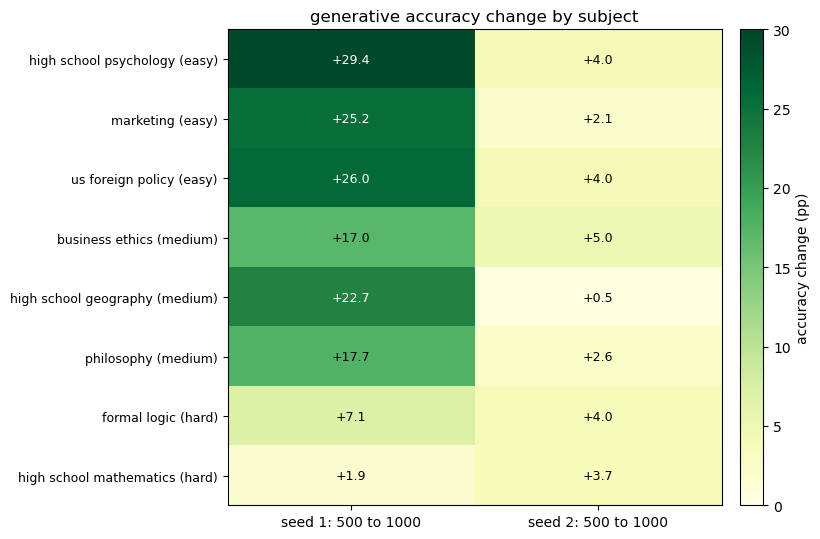

In [7]:
# compare subject-level accuracy changes across the two continuations
subjects = sorted({r['subject'] for r in paths[1]['rows500']},
                  key=lambda s: (list(TIERS).index(tier_of(s)), s))
matrix = []
for subject in subjects:
    row = []
    for seed in (1, 2):
        before = [r['correct'] for r in paths[seed]['rows500'] if r['subject'] == subject]
        after = [r['correct'] for r in paths[seed]['rows1000'] if r['subject'] == subject]
        row.append((sum(after) / len(after) - sum(before) / len(before)) * 100)
    matrix.append(row)
matrix = np.array(matrix)

fig, ax = plt.subplots(figsize=(8.5, 5.5))
im = ax.imshow(matrix, cmap='YlGn', vmin=0, vmax=30, aspect='auto')
ax.set_xticks([0, 1])
ax.set_xticklabels(['seed 1: 500 to 1000', 'seed 2: 500 to 1000'])
ax.set_yticks(np.arange(len(subjects)))
ax.set_yticklabels([f'{s.replace("_", " ")} ({tier_of(s)})' for s in subjects], fontsize=9)
for i in range(matrix.shape[0]):
    for j in range(matrix.shape[1]):
        color = heatmap_text_color(im, matrix[i, j])
        ax.text(j, i, f'{matrix[i, j]:+.1f}', ha='center', va='center', fontsize=9, color=color)
cbar = fig.colorbar(im, ax=ax, pad=0.03)
cbar.set_label('accuracy change (pp)')
ax.set_title('generative accuracy change by subject')
fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, 'fig_subject_changes.png'), dpi=200, bbox_inches='tight')
plt.show()

## Cross-referenced conclusion

Both restarted continuations produced material generative gains under their
registered rules. Seed 1 improved from 31.5% to 51.5% (+20.0 pp), while seed 2
improved from 50.6% to 53.8% (+3.2 pp). The seed 2 equivalence expectation was
therefore contradicted: the restarted phase also helped this strong artifact.

The two reward changes were similar (+.095 and +.110), but their test gains were
very different. Reward direction agreed with both improvements, but its magnitude
did not predict the size of the held-out gain. Probe accuracy remained equivalent
in both continuations. Seed 2 also became shorter and more format-compliant, so its
smaller accuracy gain includes improved answer expression rather than a measured
probe change.

Seed 2 reached 53.8%, which is inside the 53.0%-53.8% MC-SFT seed range and 0.4 pp
above its mean. This triggers the planned revision of the simple supervised-ahead
wording, but it does not show that GRPO is generally better: MC-SFT remained much
more stable and cheaper, and the two continuation artifacts were adaptively selected.
The result also does not answer how a clean 1000-step schedule planned from the
beginning would behave.